# C0 · HTO pre-screen: label noise and a forecast rule, before any HTO training (exploratory, no training)

**Why.** On ISBI the blob's shape barely reached the error, and the reading after the synthetic studies is that this depends on two
quantities: how much of the error is annotator noise (no target can remove it) and how large the blob is compared with the
network's own error, ρ = σ₀ / baseline error SD. This notebook measures the first on HTO from the three specialists, and turns the
second into a **forecast rule**: given σ₀ and the baseline error (known after one round-blob baseline), it states what the HTO arms
should show. The rule is written down here, before any HTO run, so that HTO is a prospective test.

**Data.** `data/hto/xrays/specialists_labels.json`: 54 long-leg radiographs, both legs, 6 landmarks per leg (femur_head,
knee_inner, ost_point, knee_outer, ankle_inner, ankle_outer), each marked by three specialists. Ground truth (as in the HTO paper)
= the mean of the three. Coordinates in original pixels. For direction statistics the right leg is mirrored (x → −x), so that
"medial" and "lateral" point the same way on both legs.

**Measures.**
* Per-observer noise from the deviations e_i = x_i − mean of the three: unbiased covariance Σ_obs = Σ e eᵀ / (2n) (three observers,
  two degrees of freedom per point). Robust per direction: 1.4826 × MAD of the pairwise differences / √2. Ground-truth noise
  = Σ_obs / 3 (mean of three). Systematic per-specialist offsets are reported separately (they are part of the "truth").
* κ = σ₀ / ground-truth-noise SD (unitless; on a given canvas). On ISBI κ is computed the same way from the two annotators, and
  m = baseline error SD / ground-truth-noise SD is measured there (High tier, robust). Then ρ = κ / m and the label share = 1 / m².
* **Widening rule**, fitted on the existing ISBI (High, Medium) and synthetic widened-axis points (ratio-4 oval long axis = 2σ₀):
  Δ log SD = ½ log(1 + 3kρ²), one parameter k; the ratio-2 long axis (1.41σ₀) gives ½ log(1 + kρ²). It is the additive form
  SD² = s² + k·σ_d² evaluated at ρ; on the widened axes it describes ISBI and synthetic as one curve (the narrowed axes it does not,
  which is why narrowing is forecast separately, by rule).
* **Narrowing rule** (from the evidence, not a fit): with label share ≥ 0.3 (ISBI: 0.4–0.6) narrowing changed log SD by < 0.03
  (TOST at both tiers); with exact labels (synthetic, ρ ≥ 5) by about −0.2. HTO is forecast by the same rule.

**Status.** Exploratory, written after the ISBI and synthetic results, before any HTO run. Outputs go to
`weights/C0/analyses/hto_prescreen/`. Once the five round-blob B0 runs (`C0_HTO_High_B0*.ipynb`, 5 folds × seed 101) are in
`B0_RUN_ROOT`, §5 measures m per landmark and turns the rule into point forecasts.

In [1]:
import os
REPO = os.environ.get("C0_REPO", os.path.abspath("../.."))   # notebook sits in notebooks/C0_HTO
CANVAS_LONG_SIDE = [384, 512, 768, 1024]     # candidate HTO canvases: long side (image height) in px, aspect kept
SIGMA0_CANVAS_PX = [3.54, 5.0, 7.07]         # candidate σ₀ on the canvas (ISBI High used 5 px)
M_GRID = [1.2, 1.5, 2.0, 3.0]                # baseline error SD ÷ ground-truth-noise SD (ISBI High: measured in §3)
B0_RUN_ROOT = None                           # folder with the 5 HTO B0 runs (C0_HTO_High_B0 notebooks); None = repo weights/C0/HTO_High
N_BOOT = 2000

## 0. Setup

In [2]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

REPO = Path(REPO)
HTO = REPO / "data" / "hto" / "xrays"
OUT = REPO / "weights" / "C0" / "analyses" / "hto_prescreen"
OUT.mkdir(parents=True, exist_ok=True)
ISBI_NOISE = REPO / "weights" / "C0" / "analyses" / "annotation_noise" / "annotation_noise_by_landmark.csv"
CURVE_PTS = REPO / "weights" / "C0" / "SYNTH" / "synth_summary" / "transfer_vs_target_to_error_ratio.csv"
ISBI_MM_PER_PX, ISBI_SIGMA0_PX = 0.3125, {"High": 5.0, "Medium": 7.07}
LMS = ["femur_head", "knee_inner", "ost_point", "knee_outer", "ankle_inner", "ankle_outer"]
MAD = lambda x: 1.4826 * np.median(np.abs(np.asarray(x) - np.median(x)))
rng = np.random.default_rng(20261011)
for p in (HTO / "specialists_labels.json", HTO / "hto_annotations.json", ISBI_NOISE, CURVE_PTS):
    assert p.exists(), p
print("inputs found | outputs ->", OUT)

inputs found | outputs -> C:\Users\nearl\Desktop\probable-umbrella\weights\C0\analyses\hto_prescreen


## 1. The three specialists' labels

In [3]:
S = json.loads((HTO / "specialists_labels.json").read_text(encoding="utf-8"))
rows = []
for sp_key, imgs in S.items():
    sp = sp_key.rstrip("/").split("/")[-1]
    for img, sides in imgs.items():
        for side, lms in sides.items():
            for lm, xy in lms.items():
                rows.append({"specialist": sp, "image": img, "side": side, "landmark": lm, "x": xy["x"], "y": xy["y"]})
L = pd.DataFrame(rows)
H_IMG = {im["file_name"]: im["height"] for im in json.loads((HTO / "hto_annotations.json").read_text(encoding="utf-8"))["images"]}
L["img_h"] = L.image.map(H_IMG)
W = L.pivot_table(index=["image", "side", "landmark"], columns="specialist", values=["x", "y"])
SPS = sorted(L.specialist.unique())
assert len(SPS) == 3 and W.notna().all().all(), "every point needs all three specialists"
print(f"{L.image.nunique()} radiographs, {W.index.droplevel(2).nunique()} legs, {len(W)} landmark points, specialists {SPS}")
print("image height (px): median", int(np.median(list(H_IMG.values()))), "| range", min(H_IMG.values()), "-", max(H_IMG.values()))

54 radiographs, 108 legs, 648 landmark points, specialists ['specialist1', 'specialist2', 'specialist3']
image height (px): median 7709 | range 6339 - 9289


## 2. Observer noise per landmark (original pixels; right leg mirrored)

In [4]:
X = np.stack([W["x"][s].values for s in SPS], 1)          # (n, 3)
Y = np.stack([W["y"][s].values for s in SPS], 1)
mirror = np.where(W.index.get_level_values("side") == "right", -1.0, 1.0)[:, None]
EX, EY = (X - X.mean(1, keepdims=True)) * mirror, Y - Y.mean(1, keepdims=True)
LMIDX = W.index.get_level_values("landmark")
pairs = [(0, 1), (0, 2), (1, 2)]

def axes_of(C):
    ev, V = np.linalg.eigh(C)
    ang = (math.degrees(math.atan2(V[1, 1], V[0, 1])) + 90) % 180 - 90
    return ang, ev[::-1]

noise = []
for lm in LMS:
    sel = LMIDX == lm
    ex, ey = EX[sel], EY[sel]
    n = sel.sum()
    C_obs = np.array([[np.sum(ex * ex), np.sum(ex * ey)], [np.sum(ex * ey), np.sum(ey * ey)]]) / (2 * n)
    ang, ev = axes_of(C_obs)
    a = math.radians(ang); u, v = np.array([math.cos(a), math.sin(a)]), np.array([-math.sin(a), math.cos(a)])
    dx = np.concatenate([(X[sel][:, i] - X[sel][:, j]) * mirror[sel][:, 0] for i, j in pairs])
    dy = np.concatenate([Y[sel][:, i] - Y[sel][:, j] for i, j in pairs])
    rob = {d: MAD(np.c_[dx, dy] @ vec) / math.sqrt(2) for d, vec in (("u", u), ("v", v))}
    dist = np.hypot(dx, dy)
    bias = {s: (float(np.median(ex[:, k])), float(np.median(ey[:, k]))) for k, s in enumerate(SPS)}
    noise.append({"landmark": lm, "n_points": int(n), "angle_major_deg": ang,
                  "obs_sd_major_px": math.sqrt(ev[0]), "obs_sd_minor_px": math.sqrt(max(ev[1], 0)),
                  "obs_sd_major_robust_px": rob["u"], "obs_sd_minor_robust_px": rob["v"],
                  "anisotropy_robust": rob["u"] / rob["v"],
                  "gt_sd_major_robust_px": rob["u"] / math.sqrt(3), "gt_sd_minor_robust_px": rob["v"] / math.sqrt(3),
                  "pair_dist_median_px": float(np.median(dist)), "pair_dist_p95_px": float(np.percentile(dist, 95)),
                  "max_specialist_offset_px": max(math.hypot(*b) for b in bias.values()),
                  **{f"offset_{s}_px": f"({b[0]:.1f}, {b[1]:.1f})" for s, b in bias.items()}})
NOISE = pd.DataFrame(noise)
NOISE.round(3).to_csv(OUT / "hto_observer_noise_by_landmark.csv", index=False)
NOISE[["landmark", "angle_major_deg", "obs_sd_major_robust_px", "obs_sd_minor_robust_px", "anisotropy_robust",
       "gt_sd_major_robust_px", "gt_sd_minor_robust_px", "pair_dist_median_px", "pair_dist_p95_px", "max_specialist_offset_px"]].round(2)

,landmark,angle_major_deg,obs_sd_major_robust_px,obs_sd_minor_robust_px,anisotropy_robust,gt_sd_major_robust_px,gt_sd_minor_robust_px,pair_dist_median_px,pair_dist_p95_px,max_specialist_offset_px
0,femur_head,35.92,11.26,8.18,1.38,6.50,4.72,18.24,39.35,9.91
1,knee_inner,-5.93,10.83,3.75,2.89,6.26,2.17,12.87,28.47,10.18
2,ost_point,-24.70,32.88,16.83,1.95,18.98,9.72,49.06,103.31,35.63
3,knee_outer,11.69,11.59,3.56,3.26,6.69,2.05,13.80,37.33,11.45
4,ankle_inner,-15.50,8.02,3.47,2.31,4.63,2.00,9.33,21.85,5.51
5,ankle_outer,7.61,8.83,3.54,2.49,5.10,2.05,10.51,30.10,7.78


## 3. κ = σ₀ / ground-truth noise on candidate canvases, next to ISBI (where m = error / noise is measured)

In [5]:
H_MED = float(np.median(list(H_IMG.values())))
kap = []
for c in CANVAS_LONG_SIDE:
    scale = c / H_MED                              # canvas px per original px
    for s0 in SIGMA0_CANVAS_PX:
        for _, r in NOISE.iterrows():
            for d in ("major", "minor"):
                gt_c = r[f"gt_sd_{d}_robust_px"] * scale
                kap.append({"dataset": "HTO", "canvas_long_px": c, "sigma0_canvas_px": s0, "landmark": r.landmark, "direction": d,
                            "gt_sd_canvas_px": gt_c, "kappa": s0 / gt_c})
ISB = pd.read_csv(ISBI_NOISE)
for t, g in ISB.groupby("tier"):
    for _, r in g.iterrows():
        gt_c = r.gt_noise_sd_robust_mm / ISBI_MM_PER_PX
        kap.append({"dataset": f"ISBI {t}", "canvas_long_px": 768, "sigma0_canvas_px": ISBI_SIGMA0_PX[t], "landmark": r["name"],
                    "direction": {"u": "major", "v": "minor"}[r.direction], "gt_sd_canvas_px": gt_c, "kappa": ISBI_SIGMA0_PX[t] / gt_c,
                    "m": r.err_sd_robust_mm / r.gt_noise_sd_robust_mm, "rho": ISBI_SIGMA0_PX[t] * ISBI_MM_PER_PX / r.err_sd_robust_mm})
KAP = pd.DataFrame(kap)
KAP.round(4).to_csv(OUT / "hto_kappa_by_canvas.csv", index=False)
M_ISBI = KAP[KAP.dataset == "ISBI High"].m.median()
KS = (KAP.groupby(["dataset", "canvas_long_px", "sigma0_canvas_px", "direction"])
      .agg(gt_sd_canvas_px=("gt_sd_canvas_px", "median"), kappa_median=("kappa", "median"),
           kappa_min=("kappa", "min"), kappa_max=("kappa", "max")).reset_index())
print(f"ISBI High: median m = error SD / ground-truth noise SD = {M_ISBI:.2f} (label share {1 / M_ISBI ** 2:.2f}); "
      f"median ρ = {KAP[KAP.dataset == 'ISBI High'].rho.median():.2f}")
KS.round(2)

ISBI High: median m = error SD / ground-truth noise SD = 1.43 (label share 0.49); median ρ = 2.54


,dataset,canvas_long_px,sigma0_canvas_px,direction,gt_sd_canvas_px,kappa_median,kappa_min,kappa_max
0,HTO,384,3.54,major,0.32,11.15,3.74,15.35
1,HTO,384,3.54,minor,0.11,33.69,7.31,35.51
2,HTO,384,5.00,major,0.32,15.74,5.29,21.69
3,HTO,384,5.00,minor,0.11,47.59,10.33,50.15
4,HTO,384,7.07,major,0.32,22.26,7.48,30.67
5,HTO,384,7.07,minor,0.11,67.29,14.61,70.92
6,HTO,512,3.54,major,0.42,8.36,2.81,11.52
7,HTO,512,3.54,minor,0.14,25.27,5.49,26.63
8,HTO,512,5.00,major,0.42,11.81,3.97,16.27
9,HTO,512,5.00,minor,0.14,35.69,7.75,37.61


## 4. The widening rule, fitted on ISBI (High, Medium) and synthetic widened-axis points

In [6]:
P = pd.read_csv(CURVE_PTS)
PL = P[P.axis == "long"].dropna(subset=["rho", "dlog"]).copy()
f_w = lambda rho, k, r2=3.0: 0.5 * np.log1p(r2 * k * rho ** 2)

def fit_k(df):
    res = optimize.minimize_scalar(lambda k: np.sum((df.dlog - f_w(df.rho, k)) ** 2), bounds=(1e-6, 0.2), method="bounded")
    return res.x

K_ALL = fit_k(PL)
K_DS = {ds: fit_k(g) for ds, g in PL.groupby("dataset")}
boot = []
for _ in range(N_BOOT):
    bs = pd.concat([g.sample(len(g), replace=True, random_state=int(rng.integers(1 << 31))) for _, g in PL.groupby("dataset")])
    boot.append(fit_k(bs))
K_CI = np.percentile(boot, [2.5, 97.5])
PL["resid"] = PL.dlog - f_w(PL.rho, K_ALL)
RES_SD = PL.resid.std(ddof=1)
by_ds = PL.groupby("dataset").agg(n=("resid", "size"), mean_resid=("resid", "mean"), rmse=("resid", lambda r: float(np.sqrt(np.mean(r ** 2)))))
by_ds["k_own"] = pd.Series(K_DS)
print(f"pooled k = {K_ALL:.4f} [95% bootstrap {K_CI[0]:.4f}, {K_CI[1]:.4f}] | residual SD {RES_SD:.3f}")
by_ds.round(4)

pooled k = 0.0078 [95% bootstrap 0.0059, 0.0104] | residual SD 0.160


,n,mean_resid,rmse,k_own
dataset,,,,
ISBI High,30,0.0033,0.0656,0.0067
ISBI Medium,31,-0.0114,0.0766,0.0065
synthetic,30,0.0164,0.2571,0.0082


## 5. Forecast rule for the HTO arms (and point forecasts if a baseline is available)

For each candidate canvas, σ₀ and m: ρ = κ / m per landmark and direction (median reported), label share 1/m²; widened-axis Δ for
ratio 4 (2σ₀) and ratio 2 (1.41σ₀) from the rule, with a 95 % prediction band (± 1.96 residual SD, plus the k interval);
narrowed-axis Δ by the narrowing rule; α implied for the plan's HTO design (ratios 2 and 4, both axes, OLS with intercept), with
the narrowed axes at their forecast value.

In [7]:
H2 = math.log(2)
XS = np.array([-H2, -H2 / 2, H2 / 2, H2])                 # log(σ_d/σ₀): r4 short, r2 short, r2 long, r4 long

def implied_alpha(d_r2, d_r4, d_short=0.0):
    y = np.array([d_short, d_short / 2, d_r2, d_r4])
    return float(np.polyfit(XS, y, 1)[0])

def narrowing_rule(label_share, rho):
    if label_share >= 0.3:
        return 0.0, "label share ≥ 0.3: no narrowing gain (|Δ| < 0.03), as on ISBI"
    if rho >= 5:
        return -0.2, "label share < 0.3 and ρ ≥ 5: narrowing gain about −0.2, as in synthetic"
    return np.nan, "outside the observed regimes: no forecast for narrowing"

fc = []
for (c, s0), g in KAP[KAP.dataset == "HTO"].groupby(["canvas_long_px", "sigma0_canvas_px"]):
    for m in M_GRID + [round(M_ISBI, 2)]:
        rho = float(np.median(g.kappa / m))
        share = 1 / m ** 2
        d4, d2 = float(f_w(rho, K_ALL)), float(f_w(rho, K_ALL, 1.0))
        d4_lo, d4_hi = float(f_w(rho, K_CI[0])) - 1.96 * RES_SD, float(f_w(rho, K_CI[1])) + 1.96 * RES_SD
        dn, why = narrowing_rule(share, rho)
        fc.append({"canvas_long_px": c, "sigma0_canvas_px": s0, "m": m, "m_is_isbi": m == round(M_ISBI, 2), "label_share": share,
                   "rho_median": rho, "rho_range": f"{(g.kappa / m).min():.1f}–{(g.kappa / m).max():.1f}",
                   "dlog_wide_r4": d4, "dlog_wide_r4_pi95": f"[{d4_lo:.2f}, {d4_hi:.2f}]", "dlog_wide_r2": d2,
                   "dlog_narrow_forecast": dn, "narrowing_rule": why,
                   "alpha_implied": implied_alpha(d2, d4, 0.0 if np.isnan(dn) else dn)})
FC = pd.DataFrame(fc)
FC.round(4).to_csv(OUT / "hto_forecast_grid.csv", index=False)
print("rows with m = ISBI's measured value (the default forecast until an HTO baseline exists):")
FC[FC.m_is_isbi][["canvas_long_px", "sigma0_canvas_px", "m", "label_share", "rho_median", "rho_range", "dlog_wide_r4",
                  "dlog_wide_r4_pi95", "dlog_wide_r2", "dlog_narrow_forecast", "alpha_implied"]].round(3)

rows with m = ISBI's measured value (the default forecast until an HTO baseline exists):


,canvas_long_px,sigma0_canvas_px,m,label_share,rho_median,rho_range,dlog_wide_r4,dlog_wide_r4_pi95,dlog_wide_r2,dlog_narrow_forecast,alpha_implied
4,384,3.54,1.43,0.489,10.139,2.6–24.8,0.613,"[0.21, 1.03]",0.294,0.0,0.438
9,384,5.00,1.43,0.489,14.320,3.7–35.1,0.879,"[0.46, 1.31]",0.478,0.0,0.645
14,384,7.07,1.43,0.489,20.249,5.2–49.6,1.180,"[0.74, 1.62]",0.717,0.0,0.888
19,512,3.54,1.43,0.489,7.604,2.0–18.6,0.428,"[0.04, 0.83]",0.186,0.0,0.301
24,512,5.00,1.43,0.489,10.740,2.8–26.3,0.654,"[0.25, 1.07]",0.321,0.0,0.470
29,512,7.07,1.43,0.489,15.187,3.9–37.2,0.928,"[0.50, 1.36]",0.515,0.0,0.684
34,768,3.54,1.43,0.489,5.069,1.3–12.4,0.235,"[-0.12, 0.61]",0.091,0.0,0.162
39,768,5.00,1.43,0.489,7.160,1.8–17.5,0.394,"[0.01, 0.79]",0.168,0.0,0.276
44,768,7.07,1.43,0.489,10.124,2.6–24.8,0.612,"[0.21, 1.03]",0.294,0.0,0.438
49,1024,3.54,1.43,0.489,3.802,1.0–9.3,0.146,"[-0.20, 0.50]",0.053,0.0,0.099


In [8]:
B0_ROOT = Path(B0_RUN_ROOT) if B0_RUN_ROOT else REPO / "weights" / "C0" / "HTO_High"
B0_RUNS = [B0_ROOT / f"C0_HTO_High_R_w1.00_f{f}_s101" for f in range(1, 6)]
B0_READY = all((d / "DONE").exists() for d in B0_RUNS)
POINT = None
if not B0_READY:
    print(f"HTO B0 runs not (all) present in {B0_ROOT}: the forecast stays the rule above. Train them with "
          "C0_HTO_High_B0*.ipynb (one wave), download them there and re-run this notebook.")
else:
    cfg0 = json.loads((B0_RUNS[0] / "config.json").read_text())
    hashes = {(d / "DONE").read_text().split()[0] for d in B0_RUNS}
    assert len(hashes) == 1 and hashes == {cfg0["protocol_hash"]}, f"B0 runs differ in protocol: {hashes}"
    prot = cfg0["protocol"]
    H_CAN, W_CAN = prot["canvas_hw"]
    S0_CAN = float(cfg0["sigma0_px"])
    GROSS = prot["gross_failure_mm"]                       # original px (HTO protocol: pixel_mm = 1)
    IMSZ = {int(im["file_name"].split("_")[0]): (im["width"], im["height"])
            for im in json.loads((HTO / "hto_annotations.json").read_text(encoding="utf-8"))["images"]}
    pr = pd.concat([pd.read_csv(d / "predictions_test.csv.gz") for d in B0_RUNS], ignore_index=True)
    pr = pr[(pr.checkpoint == "final") & (pr.decoder == prot["primary_decoder"])].copy()
    assert pr.groupby("run_id").image_id.nunique().sum() == pr.image_id.nunique() == 54 or prot.get("smoke_test"), "each film once"
    pr["leg"] = np.where(pr.landmark <= 6, "left", "right")
    pr["name"] = [LMS[(k - 1) % 6] for k in pr.landmark]
    pr["dxm"] = np.where(pr.leg == "right", -pr.dx_mm, pr.dx_mm)          # mirrored, original px
    pr["dym"] = pr.dy_mm
    pr["s0_orig"] = [S0_CAN / min(H_CAN / IMSZ[i][1], W_CAN / IMSZ[i][0]) for i in pr.image_id]
    rows = []
    for _, r in NOISE.iterrows():
        g = pr[pr.name == r.landmark]
        a = math.radians(r.angle_major_deg)
        for d, vec, gt in (("major", np.array([math.cos(a), math.sin(a)]), r.gt_sd_major_robust_px),
                           ("minor", np.array([-math.sin(a), math.cos(a)]), r.gt_sd_minor_robust_px)):
            e = np.concatenate([(h[["dxm", "dym"]].values @ vec) - np.median(h[["dxm", "dym"]].values @ vec)
                                for _, h in g.groupby("run_id")])
            ok = g.r_mm.values <= GROSS
            sd_cut = float(np.std(e[ok], ddof=1)) if ok.sum() > 2 else np.nan
            sd_rob = MAD(e)
            m = sd_rob / gt
            rho = float(g.s0_orig.median()) / sd_cut if np.isfinite(sd_cut) else np.nan
            share = 1 / m ** 2
            dn, why = narrowing_rule(share, rho) if np.isfinite(rho) else (np.nan, "no usable errors")
            rows.append({"landmark": r.landmark, "direction": d, "fail_rate": float(1 - ok.mean()), "err_sd_cut_px": sd_cut,
                         "err_sd_robust_px": sd_rob, "gt_sd_robust_px": gt, "m": m, "label_share": share,
                         "sigma0_orig_px": float(g.s0_orig.median()), "rho": rho,
                         "dlog_wide_r4": float(f_w(rho, K_ALL)), "dlog_wide_r2": float(f_w(rho, K_ALL, 1.0)),
                         "dlog_narrow_forecast": dn, "narrowing_rule": why})
    POINT = pd.DataFrame(rows)
    POINT.round(4).to_csv(OUT / "hto_point_forecast_by_landmark.csv", index=False)
    use = POINT[POINT.fail_rate <= 0.05]
    pooled = {"n_cells_usable": int(len(use)), "m_median": float(use.m.median()), "label_share_median": float(use.label_share.median()),
              "rho_median": float(use.rho.median()), "dlog_wide_r4_median": float(use.dlog_wide_r4.median()),
              "dlog_wide_r2_median": float(use.dlog_wide_r2.median()),
              "dlog_narrow_median": float(use.dlog_narrow_forecast.median()) if use.dlog_narrow_forecast.notna().any() else None,
              "protocol_hash": cfg0["protocol_hash"]}
    pooled["alpha_implied"] = implied_alpha(pooled["dlog_wide_r2_median"], pooled["dlog_wide_r4_median"],
                                            pooled["dlog_narrow_median"] or 0.0)
    (OUT / "hto_point_forecast_pooled.json").write_text(json.dumps(pooled, indent=1, default=float))
    print("pooled point forecast (usable cells, ≤ 5 % gross failures):", {k: (round(v, 3) if isinstance(v, float) else v)
                                                                         for k, v in pooled.items()})
    display(POINT.round(3))

HTO B0 runs not (all) present in C:\Users\nearl\Desktop\probable-umbrella\weights\C0\HTO_High: the forecast stays the rule above. Train them with C0_HTO_High_B0*.ipynb (one wave), download them there and re-run this notebook.


## 6. Figure

saved: ['hto_forecast_grid.csv', 'hto_kappa_by_canvas.csv', 'hto_observer_noise_by_landmark.csv', 'hto_prescreen.png', 'hto_prescreen_summary.json']


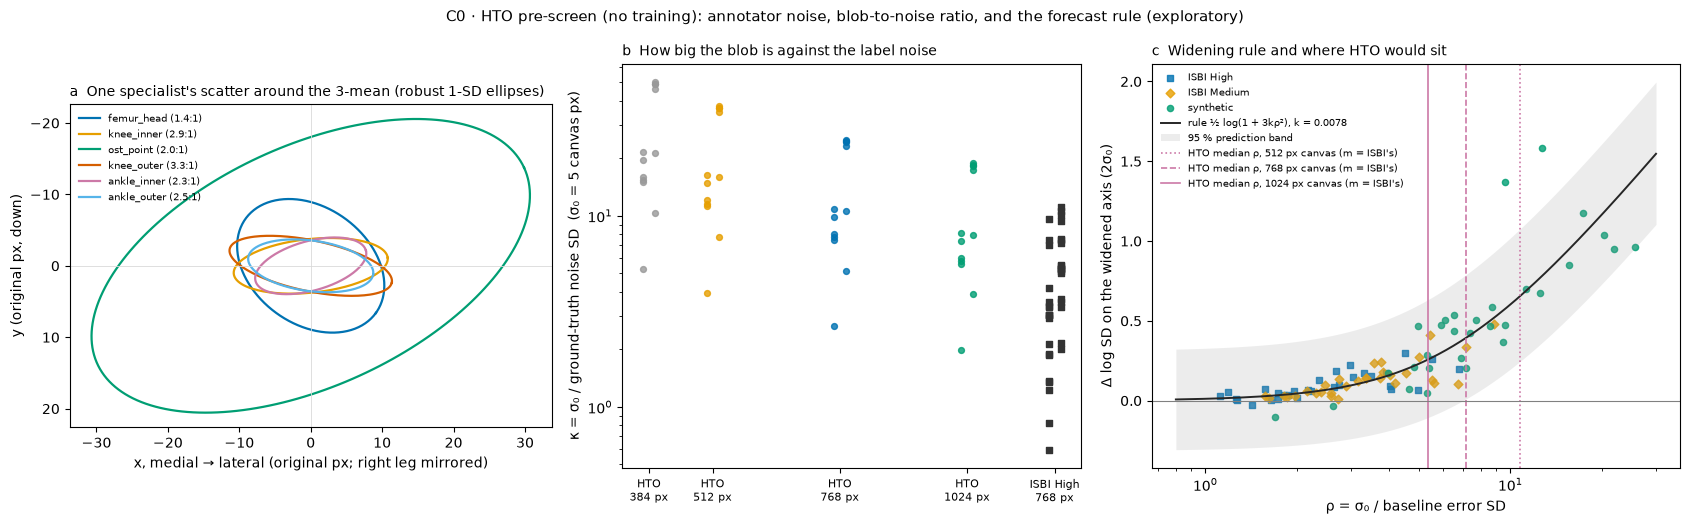

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(17, 5.3), gridspec_kw={"width_ratios": [1.05, 1, 1.15]})
ax = axs[0]
cols = dict(zip(LMS, ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]))
tt = np.linspace(0, 2 * np.pi, 200)
for k, r in NOISE.iterrows():
    a = math.radians(r.angle_major_deg)
    R_ = np.array([[math.cos(a), -math.sin(a)], [math.sin(a), math.cos(a)]])
    e = R_ @ np.vstack([r.obs_sd_major_robust_px * np.cos(tt), r.obs_sd_minor_robust_px * np.sin(tt)])
    ax.plot(e[0], e[1], color=cols[r.landmark], lw=1.6, label=f"{r.landmark} ({r.anisotropy_robust:.1f}:1)")
ax.set_aspect("equal"); ax.axhline(0, color="0.85", lw=0.6); ax.axvline(0, color="0.85", lw=0.6)
ax.set_xlabel("x, medial → lateral (original px; right leg mirrored)"); ax.set_ylabel("y (original px, down)")
ax.invert_yaxis(); ax.legend(fontsize=7.5, frameon=False, loc="upper left")
ax.set_title("a  One specialist's scatter around the 3-mean (robust 1-SD ellipses)", fontsize=10, loc="left")

ax = axs[1]
cl = {384: "#999999", 512: "#E69F00", 768: "#0072B2", 1024: "#009E73"}
s0_ref = 5.0
for c in CANVAS_LONG_SIDE:
    g = KAP[(KAP.dataset == "HTO") & (KAP.canvas_long_px == c) & (KAP.sigma0_canvas_px == s0_ref)]
    ax.scatter(np.full(len(g), c) + np.where(g.direction == "major", -12, 12), g.kappa, s=18, color=cl[c], alpha=0.8)
gi = KAP[KAP.dataset == "ISBI High"]
ax.scatter(np.full(len(gi), 1200) + np.where(gi.direction == "major", -12, 12), gi.kappa, s=18, color="0.2", marker="s")
ax.set_xticks(CANVAS_LONG_SIDE + [1200]); ax.set_xticklabels([f"HTO\n{c} px" for c in CANVAS_LONG_SIDE] + ["ISBI High\n768 px"], fontsize=8)
ax.set_yscale("log"); ax.set_ylabel(f"κ = σ₀ / ground-truth noise SD  (σ₀ = {s0_ref:g} canvas px)")
ax.set_title("b  How big the blob is against the label noise", fontsize=10, loc="left")

ax = axs[2]
mk = {"ISBI High": ("s", "#0072B2"), "ISBI Medium": ("D", "#E69F00"), "synthetic": ("o", "#009E73")}
for ds, g in PL.groupby("dataset"):
    ax.scatter(g.rho, g.dlog, marker=mk[ds][0], color=mk[ds][1], s=20, alpha=0.8, label=ds)
rr = np.geomspace(0.8, 30, 200)
ax.plot(rr, f_w(rr, K_ALL), color="0.15", lw=1.4, label=f"rule ½ log(1 + 3kρ²), k = {K_ALL:.4f}")
ax.fill_between(rr, f_w(rr, K_CI[0]) - 1.96 * RES_SD, f_w(rr, K_CI[1]) + 1.96 * RES_SD, color="0.6", alpha=0.18, lw=0, label="95 % prediction band")
for c, ls in ((512, ":"), (768, "--"), (1024, "-")):
    g = FC[(FC.canvas_long_px == c) & (FC.sigma0_canvas_px == s0_ref) & FC.m_is_isbi]
    if len(g):
        ax.axvline(g.rho_median.iloc[0], color="#CC79A7", ls=ls, lw=1.2, label=f"HTO median ρ, {c} px canvas (m = ISBI's)")
ax.set_xscale("log"); ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("ρ = σ₀ / baseline error SD"); ax.set_ylabel("Δ log SD on the widened axis (2σ₀)")
ax.legend(fontsize=7, frameon=False, loc="upper left")
ax.set_title("c  Widening rule and where HTO would sit", fontsize=10, loc="left")
fig.suptitle("C0 · HTO pre-screen (no training): annotator noise, blob-to-noise ratio, and the forecast rule (exploratory)", fontsize=11)
fig.tight_layout()
fig.savefig(OUT / "hto_prescreen.png", dpi=150, bbox_inches="tight")

summary = {"n_radiographs": int(L.image.nunique()), "n_legs": int(W.index.droplevel(2).nunique()), "specialists": SPS,
           "median_image_height_px": H_MED, "isbi_high_m": float(M_ISBI), "isbi_high_label_share": float(1 / M_ISBI ** 2),
           "k_pooled": float(K_ALL), "k_ci95": [float(x) for x in K_CI], "residual_sd": float(RES_SD),
           "k_by_dataset": {k: float(v) for k, v in K_DS.items()},
           "observer_noise": NOISE.round(3).to_dict("records"), "forecast_grid_file": "hto_forecast_grid.csv"}
(OUT / "hto_prescreen_summary.json").write_text(json.dumps(summary, indent=1, default=float))
print("saved:", sorted(p.name for p in OUT.iterdir()))